# Out-of-time cohorts: SME PD by vintage through 2008 (C03)

**Question:** Does a small-business PD scorecard trained before the 2008 crisis stay calibrated on the loans approved after it, and which tests of the battery say so, in which direction?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- explain why a panel of loans is validated by vintage, out of time, and why the target of a vintage is read only at its 5-year mark;
- read the five rolling training windows of C03 and see that each one closes before its test cohort is approved;
- read the observed and predicted 5-year PD of fifteen approval years and the calibration by decile;
- call the engine's level, chi-square, traffic-light, multi-period and critical-count tests on the vintages, and say why the one-sided tests stay green while the scorecard over-predicts the risk.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from datetime import date

from riskvalidation.validation.calibration import critical_default_count, pd_binomial_vasicek, pd_chi2_grades
from riskvalidation.validation.calibration import pd_default_profile, pd_jeffreys, pd_jeffreys_grades
from riskvalidation.validation.calibration import pd_normal_multiperiod, pd_traffic_lights
from matplotlib.colors import ListedColormap

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C03 is the PD of small-business loans by vintage. The data is the U.S. Small Business Administration 7(a) FOIA loan file (owner: U.S. SBA; licence "U.S. Government Works", class `mirror-allowed`; https://data.sba.gov/dataset/7a-504-foia; loans approved from fiscal year 1991, as of 2026-06-30). It is a federal guarantee programme for small-business loans, not the SME book of a bank: the file has no delinquency history, no balance and no rating (finding `F-DATA`). The pipeline fitted six models on the approval fiscal years up to a cut-off and scored five later cohorts. This notebook reads what it committed:

- `data/derived/C03/fy2006-07.json`, `fy2008-10.json`, `fy2011-14.json`, `fy2015-17.json` and `fy2018-20.json`: one file per test cohort, with the vintage summaries and curves, the calibration by decile, the comparison of the models and the battery of tests.
- `data/derived/C03/models-sba-7a.json`: the target definition, the five training windows with their cut-off dates and the ladder.

The next cell loads the six files.

In [2]:
# Load the five cohort files and the models file of case C03 (three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C03"
names = ["fy2006-07", "fy2008-10", "fy2011-14", "fy2015-17", "fy2018-20"]
cohorts = {n: json.loads((derived / f"{n}.json").read_text(encoding="utf-8")) for n in names}
fit = json.loads((derived / "models-sba-7a.json").read_text(encoding="utf-8"))["fit"]
vintages = [v for n in names for v in cohorts[n]["outputs"]["vintage_summary"]["rows"]]
policy = rv.default_policy()
LANG = "en"
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
print("test cohorts:", [cohorts[n]["outputs"]["cohort"]["label"][LANG] for n in names])
print("models in the ladder:", [r["rung_id"] for r in fit["ladder"]])
baked = cohorts[names[0]]["provenance"]["riskvalidation_version"]
print("baked by riskvalidation", baked, "| installed", rv.__version__)

test cohorts: ['FY2006-07', 'FY2008-10', 'FY2011-14', 'FY2015-17', 'FY2018-20']
models in the ladder: ['P0-constant', 'P1-scorecard', 'P2a-l1', 'P2b-pltr', 'P3-ebm', 'P4-lightgbm']
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: why a vintage, and what "out of time" means

A loan portfolio changes over time: the economy, the lenders' policies and the mix of borrowers move. A model validated on a random slice of the same years is validated on loans it could have learned from, and the future leaks into the training. The out-of-time design of C03 (the split in `docs/design/SDD.md` and the leakage rules of the research basis) answers with two rules. First, a **vintage** is the group of loans approved in one fiscal year (1 October to 30 September), and the model is trained on early vintages and tested on later ones. Second, the target of a vintage is read **only at its 5-year mark**: a loan is an event if it charged off within 60 months of approval, and a vintage enters the training only when the 60th month of its last loan has passed, so that its target is known and not censored. The cell draws, for each of the five cuts, the training years in blue, the test cohort in orange and the 5-year mark of the last training year as a black bar, and counts the windows that close before their cohort starts.

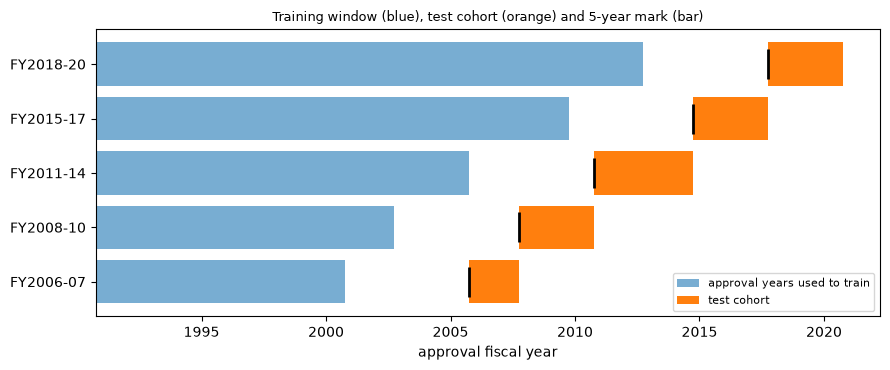

windows that close before their test cohort: 5 of 5
training loans per window: [330682, 413083, 627594, 900254, 1024597]


In [3]:
# Draw the training window and the test cohort of each cut, and count the windows that close before their cohort
fig, ax = plt.subplots(figsize=(9, 3.8))
windows = fit["cohort_windows"]
closed = 0
for k, w in enumerate(windows):
    train = w["training"]
    cutoff = date.fromisoformat(train["cutoff_date"])
    closed += int(cutoff < date(w["first_fy"] - 1, 10, 1))
    ax.barh(k, train["last_fy"] - train["first_fy"] + 1, left=train["first_fy"] - 0.25, color="tab:blue", alpha=0.6,
            label="approval years used to train" if k == 0 else None)
    ax.barh(k, w["last_fy"] - w["first_fy"] + 1, left=w["first_fy"] - 0.25, color="tab:orange",
            label="test cohort" if k == 0 else None)
    mark = cutoff.year + cutoff.timetuple().tm_yday / 366
    ax.plot(mark, k, marker="|", color="black", markersize=22, markeredgewidth=2)
ax.set_yticks(range(len(windows)), [w["label"][LANG] for w in windows])
ax.set_xlabel("approval fiscal year")
ax.set_title("Training window (blue), test cohort (orange) and 5-year mark (bar)", fontsize=9)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
print("windows that close before their test cohort:", closed, "of", len(windows))
print("training loans per window:", [w["training"]["n_loans"] for w in windows])

All five windows close before their cohort starts (5 of 5): the black bar, the 5-year mark of the last training year, sits one day before the orange bar begins. The training sets grow from 330,682 loans (FY1991 to FY2000) to 1,024,597, and from the third cut on they contain the outcomes of the 2007 to 2009 recession, which is the reason the later cohorts behave so differently from the first two. The figure does not show the censoring rule at work, which cuts the most recent years: the last test cohort ends at FY2020, because the 5-year mark of FY2021 has not passed on the file's date of 2026-06-30.

### Step 2: observed against predicted, vintage by vintage

For one vintage, the observed 5-year PD is the share of its loans that charged off within 60 months, and the predicted 5-year PD is the mean PD that the scorecard (rung P1) gave to its loans. Their difference is the calibration gap, positive when the model under-estimates the risk and negative when it over-estimates it. The AUC of the vintage says whether the ranking held. The cell draws both for the fifteen vintages, the gap in red where the risk was under-estimated and blue where it was over-estimated, and prints the extremes.

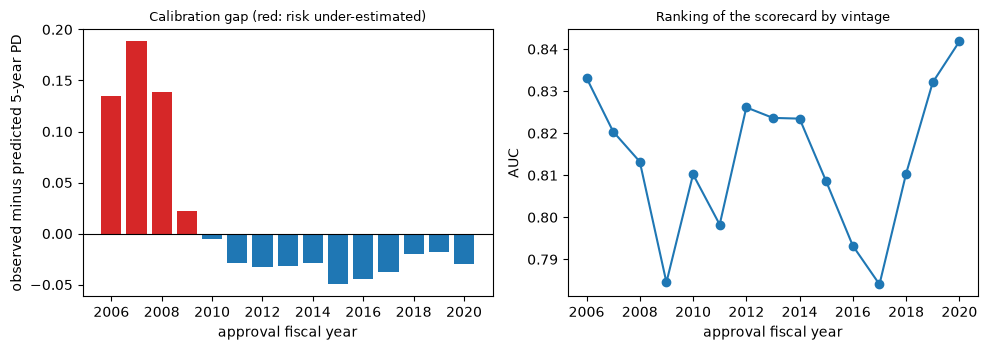

largest gap, fiscal year and size: 2007 0.1882
vintages whose risk is under-estimated: 4 of 15
lowest and highest AUC by vintage: 0.7841 0.8418


In [4]:
# Observed against predicted 5-year PD of the fifteen vintages: the gap and the AUC of each
years = [v["fiscal_year"] for v in vintages]
gap = [v["observed_5y_pd"] - v["predicted_5y_pd"] for v in vintages]
aucs = [v["auc"] for v in vintages]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(years, gap, color=["tab:red" if g > 0 else "tab:blue" for g in gap])
left.axhline(0, color="black", linewidth=0.8)
left.set_xlabel("approval fiscal year")
left.set_ylabel("observed minus predicted 5-year PD")
left.set_title("Calibration gap (red: risk under-estimated)", fontsize=9)
right.plot(years, aucs, marker="o")
right.set_xlabel("approval fiscal year")
right.set_ylabel("AUC")
right.set_title("Ranking of the scorecard by vintage", fontsize=9)
fig.tight_layout()
plt.show()
print("largest gap, fiscal year and size:", years[int(np.argmax(gap))], round(max(gap), 4))
print("vintages whose risk is under-estimated:", sum(g > 0 for g in gap), "of", len(gap))
print("lowest and highest AUC by vintage:", round(min(aucs), 4), round(max(aucs), 4))

The gap is largest for FY2007, 0.1882: loans approved that year charged off at about 27.6% within five years against 8.8% predicted. Four vintages, FY2006 to FY2009, are under-estimated, and the eleven from FY2010 on are over-estimated, by up to five points, because the training windows of those cohorts contain the crisis. The AUC barely moves, between 0.7841 and 0.8418: the ranking holds while the level moves, which is why a model can keep its AUC and still be wrongly sized by a factor of three. The figure shows the problem and the sign; the engine's tests say whether it is large enough to reject.

### Step 3: the level tests on each cohort

A cohort has $N$ loans, $D$ charge-offs and a mean predicted PD, and the vintage summaries hold all three, so the engine can be called on them. The cell rebuilds them for each of the five cohorts and calls the Jeffreys test (Brown, Cai and DasGupta, 2001) and the Vasicek-adjusted binomial test with an asset correlation of 0.12 (BCBS, 2005), a modelling assumption that the committed rows state in their notes. Both are one-sided: they reject when the defaults exceed what the PD allows, and a PD that is too high is never rejected.

In [5]:
# Rebuild N, D and the mean PD of each cohort from its vintages and call the engine's two level tests
kw = dict(policy=policy, model_id="P1-scorecard", segment="portfolio")
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    total = sum(v["n"] for v in rows)
    hits = sum(round(v["observed_5y_pd"] * v["n"]) for v in rows)
    mean_pd = sum(v["predicted_5y_pd"] * v["n"] for v in rows) / total
    jef = pd_jeffreys(total, hits, mean_pd, **kw)
    vas = pd_binomial_vasicek(total, hits, mean_pd, 0.12, **kw)
    print(n, "cohort, loans, charge-offs, mean PD:", total, hits, round(mean_pd, 4))
    print("   Jeffreys p:", round(jef.p_value, 4))
    print("   Vasicek p and light:", round(vas.p_value, 4), LIGHT[vas.light.value])

fy2006-07 cohort, loans, charge-offs, mean PD: 174527 43581 0.0878
   Jeffreys p: 0.0
   Vasicek p and light: 0.0154 amber
fy2008-10 cohort, loans, charge-offs, mean PD: 138023 18108 0.0647
   Jeffreys p: 0.0
   Vasicek p and light: 0.0845 green
fy2011-14 cohort, loans, charge-offs, mean PD: 170795 5790 0.064
   Jeffreys p: 1.0
   Vasicek p and light: 0.7222 green
fy2015-17 cohort, loans, charge-offs, mean PD: 168203 6745 0.084
   Jeffreys p: 1.0
   Vasicek p and light: 0.7841 green
fy2018-20 cohort, loans, charge-offs, mean PD: 136291 5256 0.0607
   Jeffreys p: 1.0
   Vasicek p and light: 0.6446 green


The first two cohorts are rejected by Jeffreys with a p-value of 0.0, and the Vasicek test softens that: amber for FY2006-07 (p of 0.0154) and green for FY2008-10 (0.0845), because an asset correlation of 0.12 widens the band of defaults a portfolio may show by chance. From FY2011-14 on the Jeffreys p-value is 1.0 and the Vasicek p-value 0.7222, 0.7841 and 0.6446, all green. The reading needs care: a green light after 2010 means "the defaults are not above the PD", which is true of a model that over-predicts by a factor of two. The next figure repeats the Jeffreys test vintage by vintage.

### Step 4: which vintages reject

Cohorts average vintages that behave very differently, as the previous figures showed. `pd_jeffreys_grades` runs the one-sided Jeffreys test on each vintage separately, with its loans, its charge-offs and its mean PD, and returns one result per vintage plus one for the pooled cohort. The cell draws the p-value of each of the fifteen vintages with the colour of the engine's light, cohort by cohort, with a gap between cohorts.

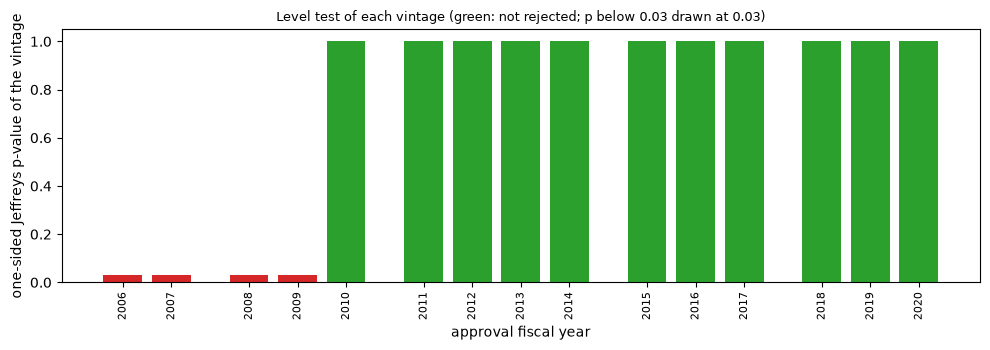

In [6]:
# The one-sided Jeffreys test of every vintage, cohort by cohort, coloured by the light the engine gives
colors = {"green": "tab:green", "amber": "gold", "red": "tab:red", "not_evaluated": "lightgray"}
fig, ax = plt.subplots(figsize=(10, 3.6))
position, ticks, labels_ = 0.0, [], []
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    n_v = [v["n"] for v in rows]
    d_v = [round(v["observed_5y_pd"] * v["n"]) for v in rows]
    p_v = [v["predicted_5y_pd"] for v in rows]
    tags = [str(v["fiscal_year"]) for v in rows]
    for r in pd_jeffreys_grades(n_v, d_v, p_v, grades=tags, policy=policy, model_id="P1-scorecard")[:-1]:
        ax.bar(position, max(r.p_value, 0.03), color=colors[r.light.value])
        ticks.append(position)
        labels_.append(r.segment)
        position += 1
    position += 0.6
ax.set_xticks(ticks, labels_, rotation=90, fontsize=8)
ax.set_xlabel("approval fiscal year")
ax.set_ylabel("one-sided Jeffreys p-value of the vintage")
ax.set_title("Level test of each vintage (green: not rejected; p below 0.03 drawn at 0.03)", fontsize=9)
fig.tight_layout()
plt.show()

The bars are red for the four vintages from FY2006 to FY2009, the ones whose risk was under-estimated (their p-values are 0.0, drawn as the shortest bar), and green with a p-value of 1.0 for the other eleven. FY2010, at the edge, is green. The pooled cohorts of the previous step blurred this: cohort FY2008-10 mixes two rejected vintages and one green one. The one-sided Jeffreys test cannot be used to say that a model is well calibrated after the crisis; it can only say that it is not too optimistic. A two-sided question needs a two-sided test.

### Step 5: two-sided tests over the vintages of a cohort

`pd_chi2_grades` takes the loans, the charge-offs and the predicted PD of several groups, here the vintages of a cohort, and sums the squared standardised differences: it rejects when any group departs from its PD in either direction (BCBS, 2005). `pd_traffic_lights` colours the groups by how many of them depart and by how much, with the probabilities of the supervisory traffic-light scheme. The cell runs both on the vintages of each cohort and prints the p-value and the light.

In [7]:
# Treat the vintages of each cohort as groups: the two-sided chi-square over vintages and the traffic-light test
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    n_v = [v["n"] for v in rows]
    d_v = [round(v["observed_5y_pd"] * v["n"]) for v in rows]
    p_v = [v["predicted_5y_pd"] for v in rows]
    chi = pd_chi2_grades(n_v, d_v, p_v, policy=policy, model_id="P1-scorecard", segment="portfolio")
    light = pd_traffic_lights(n_v, d_v, p_v, policy=policy, model_id="P1-scorecard", segment="portfolio")
    p_text = float(f"{chi.p_value:.3g}")
    print(n, "chi-square over vintages, p and light:", p_text, LIGHT[chi.light.value])
    print("   traffic light:", LIGHT[light.light.value])

fy2006-07 chi-square over vintages, p and light: 0.0 red
   traffic light: red
fy2008-10 chi-square over vintages, p and light: 0.0 red
   traffic light: green
fy2011-14 chi-square over vintages, p and light: 0.0 red
   traffic light: green
fy2015-17 chi-square over vintages, p and light: 0.0 red
   traffic light: green
fy2018-20 chi-square over vintages, p and light: 9.11e-271 red
   traffic light: green


The chi-square over the vintages is red in all five cohorts, from a p-value of 0.0 to 9.11e-271 for FY2018-20: this is the test that notices the over-prediction after the crisis, since it is two-sided. The traffic-light test is red only for FY2006-07 and green for the others, so a supervisory scheme built for under-estimation misses the over-estimation too. Two tests built for the same job, then, disagree on four of five cohorts: which one to trust depends on the question, and a validator who needs to know that a model is not too conservative must choose the two-sided one.

### Step 6: the vintages as consecutive periods

A cohort of consecutive vintages is also a short time series of default rates. `pd_normal_multiperiod` takes the observed default rate and the predicted PD of each period and tests, with a normal approximation, whether the mean of the observed rates exceeds that of the PDs; it is one-sided. `pd_default_profile` simulates the number of defaults of each group under the model and asks whether the observed profile is plausible, in either direction. The cell runs both on each cohort, with 20,000 seeded simulations for the profile.

In [8]:
# The vintages of each cohort as consecutive periods: the multi-period normal test and the default-profile test
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    n_v = [v["n"] for v in rows]
    d_v = [round(v["observed_5y_pd"] * v["n"]) for v in rows]
    p_v = [v["predicted_5y_pd"] for v in rows]
    rates = [v["observed_5y_pd"] for v in rows]
    kw = dict(policy=policy, model_id="P1-scorecard", segment="portfolio")
    multi = pd_normal_multiperiod(rates, p_v, **kw)
    profile = pd_default_profile(n_v, d_v, p_v, n_sim=20000, seed=1, **kw)
    print(n, "multi-period normal test, p and light:", round(multi.p_value, 4), LIGHT[multi.light.value])
    print("   default-profile test, p:", round(profile.p_value, 4))

fy2006-07 multi-period normal test, p and light: 0.0 red
   default-profile test, p: 0.0
fy2008-10 multi-period normal test, p and light: 0.1194 green
   default-profile test, p: 0.0
fy2011-14 multi-period normal test, p and light: 1.0 green
   default-profile test, p: 0.0004
fy2015-17 multi-period normal test, p and light: 1.0 green
   default-profile test, p: 0.0
fy2018-20 multi-period normal test, p and light: 1.0 green
   default-profile test, p: 0.0


The multi-period normal test is red only for FY2006-07 (p of 0.0), green for FY2008-10 (0.1194) and has a p-value of 1.0 after that, so it behaves like the Jeffreys test: it sees under-estimation only. The default-profile test, which is two-sided, gives p-values of 0.0 for four cohorts and 0.0004 for FY2011-14, so it agrees with the chi-square. The family of two-sided tests is consistent and the family of one-sided tests is consistent with itself, and they are different families.

### Step 7: how many defaults is too many?

A level test is also a tolerance: the number of defaults a portfolio of $n$ loans with PD $p$ may show before the test rejects at 99%. With the Vasicek asset correlation of 0.12, `critical_default_count` returns that number. The ratio of the observed charge-offs to the tolerated number is below 1 inside the tolerance and above 1 outside. The cell computes it for all fifteen vintages and draws it, in red above 1.

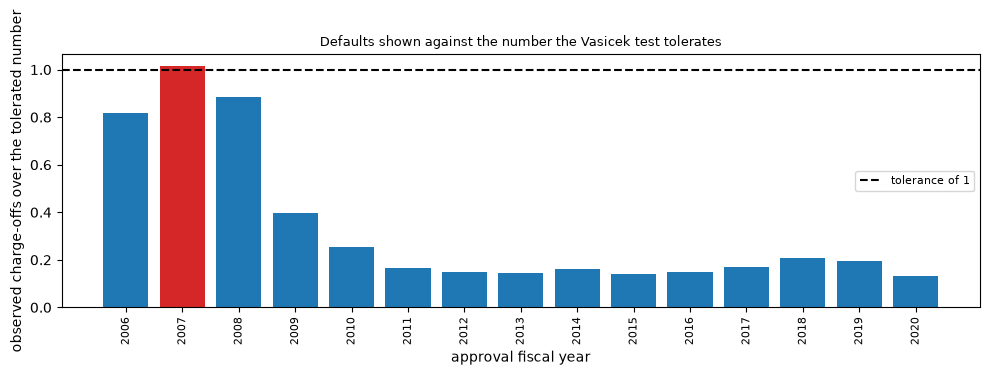

vintages above the tolerance: [2007]
vintage with the largest ratio, and the ratio: 2007 1.014


In [9]:
# The charge-offs a vintage may show before the Vasicek test rejects (99%, correlation 0.12), against the observed
shown = np.array([round(v["observed_5y_pd"] * v["n"]) for v in vintages])
limit = np.array([critical_default_count(v["n"], v["predicted_5y_pd"], 0.99, 0.12) for v in vintages])
ratio = shown / limit
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar([str(v["fiscal_year"]) for v in vintages], ratio, color=np.where(ratio > 1, "tab:red", "tab:blue"))
ax.axhline(1, color="black", linestyle="--", label="tolerance of 1")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.set_xlabel("approval fiscal year")
ax.set_ylabel("observed charge-offs over the tolerated number")
ax.set_title("Defaults shown against the number the Vasicek test tolerates", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("vintages above the tolerance:", [v["fiscal_year"] for v, r in zip(vintages, ratio) if r > 1])
print("vintage with the largest ratio, and the ratio:", years[int(np.argmax(ratio))], round(float(ratio.max()), 3))

Only one vintage, FY2007, is above the tolerance, at a ratio of 1.014, and FY2006, FY2008 and the others are inside it. The band of the Vasicek test is wide for a portfolio of this size: with a correlation of 0.12 the portfolio's default count can move by tens of percent without a rejection, and 99% is the supervisory quantile for capital, not for a conservative validation. The vintages that the Jeffreys test rejects with a p-value near 0 are inside the wider tolerance of the Vasicek-adjusted test, a reminder that "reject" depends on the assumed correlation.

### Step 8: calibration by decile

A portfolio hides where the model is wrong. The committed calibration groups the loans of a cohort into ten deciles of PD and gives, for each, the predicted PD, the observed rate and a 95% interval of the observed rate. The cell counts, for each cohort, the deciles whose predicted PD falls above and below that interval, and draws the ten deciles of FY2015-17 on logarithmic axes, with the diagonal as perfect calibration.

fy2006-07 deciles with the predicted PD above the interval: 0 | below: 10
fy2008-10 deciles with the predicted PD above the interval: 2 | below: 6
fy2011-14 deciles with the predicted PD above the interval: 9 | below: 0
fy2015-17 deciles with the predicted PD above the interval: 9 | below: 1
fy2018-20 deciles with the predicted PD above the interval: 8 | below: 2


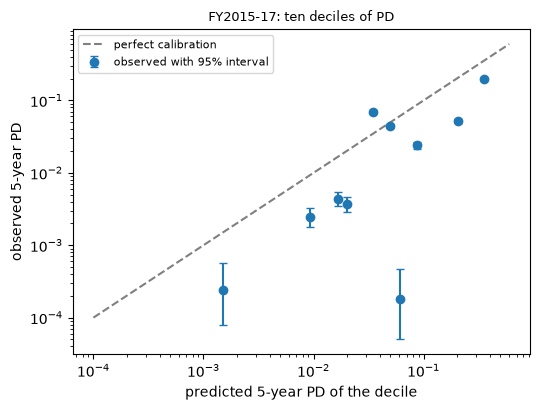

In [10]:
# Count the deciles whose predicted PD falls outside the interval of the observed rate, and draw FY2015-17
for n in names:
    rows = cohorts[n]["outputs"]["calibration"]["rows"]
    above = sum(r["predicted_pd"] > r["ci_high"] for r in rows)
    below = sum(r["predicted_pd"] < r["ci_low"] for r in rows)
    print(n, "deciles with the predicted PD above the interval:", above, "| below:", below)
rows = cohorts["fy2015-17"]["outputs"]["calibration"]["rows"]
predicted = np.array([r["predicted_pd"] for r in rows])
observed = np.array([max(r["observed_pd"], 1e-5) for r in rows])
low = np.array([max(r["ci_low"], 1e-5) for r in rows])
high = np.array([r["ci_high"] for r in rows])
fig, ax = plt.subplots(figsize=(5.5, 4.2))
err = [observed - low, high - observed]
ax.errorbar(predicted, observed, yerr=err, fmt="o", capsize=3, label="observed with 95% interval")
ax.plot([1e-4, 0.6], [1e-4, 0.6], color="gray", linestyle="--", label="perfect calibration")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("predicted 5-year PD of the decile")
ax.set_ylabel("observed 5-year PD")
ax.set_title("FY2015-17: ten deciles of PD", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In FY2006-07 all ten deciles are predicted below their interval (under-estimated), in FY2011-14 nine are above it, in FY2015-17 nine are above and one below, and in FY2018-20 eight are above and two below. In the figure of FY2015-17 the dots sit under the diagonal, and the lowest deciles are the farthest: the predicted PD of the safest loans is several times what was observed. The over-estimation is not a shift of the whole curve but a stretch of its low end. The interval says how reliable each dot is, and none of the intervals reaches the diagonal in the lowest deciles.

### Step 9: the committed battery, cohort by cohort

The cohort files commit the battery of the engine on the scorecard. The cell draws the light of six portfolio rows for the five cohorts as a grid (green, amber, red, grey where the test only describes) and prints the p-value of the AUC against development, which asks whether the ranking now has fallen below the development ranking. Read the grid by columns, as a validator would, asking which cohorts the battery objects to and by which family of tests.

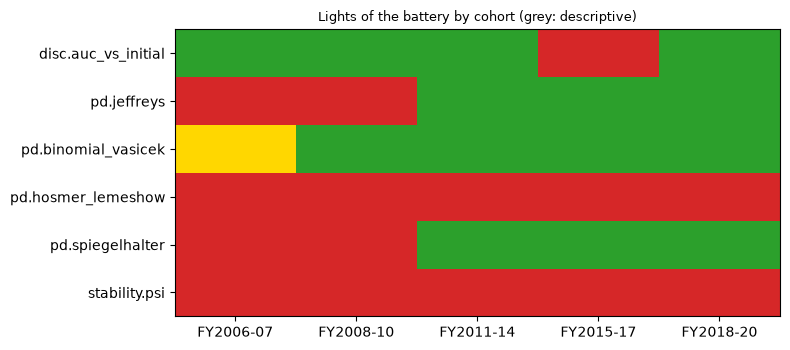

AUC against development, p by cohort: [1.0, 1.0, 0.977, 1.03e-08, 0.468]


In [11]:
# The committed battery of the scorecard by cohort: the light of each portfolio row, and the AUC against development
show = ["disc.auc_vs_initial", "pd.jeffreys", "pd.binomial_vasicek"]
show += ["pd.hosmer_lemeshow", "pd.spiegelhalter", "stability.psi"]
codes = {"not_evaluated": 0, "green": 1, "amber": 2, "red": 3}
grid = np.zeros((len(show), len(names)))
dev_p = []
for j, n in enumerate(names):
    for i, test_id in enumerate(show):
        row = next(t for t in cohorts[n]["tests"] if t["test_id"] == test_id and t["model_id"] == "P1-scorecard"
                   and t["segment"] == "portfolio")
        grid[i, j] = codes[row["light"]]
        dev_p.append(float(f"{row['p_value']:.3g}") if test_id == "disc.auc_vs_initial" else None)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.imshow(grid, cmap=ListedColormap(["lightgray", "tab:green", "gold", "tab:red"]), vmin=0, vmax=3, aspect="auto")
ax.set_xticks(range(len(names)), [cohorts[n]["outputs"]["cohort"]["label"][LANG] for n in names])
ax.set_yticks(range(len(show)), show)
ax.set_title("Lights of the battery by cohort (grey: descriptive)", fontsize=9)
fig.tight_layout()
plt.show()
print("AUC against development, p by cohort:", [p for p in dev_p if p is not None])

## Results

**Answer:** No, and the direction of the miscalibration changes: the scorecard under-estimates the risk of the vintages that straddle the crisis and over-estimates that of the later ones. All five training windows close before their test cohort starts (5 of 5). FY2007 charged off 0.1882 above its prediction, four vintages are under-estimated and eleven over-estimated, while the AUC stays between 0.7841 and 0.8418. The one-sided tests see only the first half: the Jeffreys p-value is 0.0 for FY2006-07 and FY2008-10 and 1.0 for the three later cohorts, and the Vasicek-adjusted test gives 0.0154 (amber), 0.0845, 0.7222, 0.7841 and 0.6446. The two-sided tests see both halves: the chi-square over vintages is red in all five cohorts (9.11e-271 for FY2018-20), and the default-profile test gives 0.0 or 0.0004. Within the tolerance of Step 7 (Vasicek correlation 0.12) only FY2007 is above it (ratio 1.014). The AUC against development is the one rejection in a different place, FY2015-17, with a p-value of 1.03e-08, where the ranking, not the level, fell.

This is why a validator who runs only one-sided level tests would call the model fine after 2010, while it over-predicts the risk of loans in the lowest PD deciles by a large factor: nine of ten deciles are above their interval in FY2011-14 and FY2015-17.

What this notebook does not show: the individual rows of the battery for the other five models, the cumulative PD curves by month, and the effect of retraining after the crisis. The data is a federal guarantee programme, not the SME book of a bank (finding `F-DATA`), so the figures show the method on a real panel, not the risk of a particular lender.

## Summary

- A panel is validated out of time: vintages by approval fiscal year, training windows that close on a 5-year mark before the test cohort starts, and a target read only where every loan has had its 60 months.
- The calibration of a scorecard moves by cohort: strongly under-predicted across the crisis, over-predicted after it when the training window contained the crisis, while the AUC stays between 0.78 and 0.84.
- One-sided level tests reject only an under-estimate; the chi-square over vintages, the default-profile test and the decile intervals also see the over-estimate that ties capital up.
- A pooled cohort hides what the vintages show: run the level test per vintage, and read tolerance as a function of the assumed correlation.

**What to try next.** Change the asset correlation of the critical count from 0.12 to 0.05 or 0.20 and see how many vintages leave the tolerance; then continue with notebook 05, which applies the same discipline to corporate PD at one to five year horizons.

## References

- U.S. Small Business Administration, 7(a) and 504 FOIA loan data (U.S. Government Works). https://data.sba.gov/dataset/7a-504-foia
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 and 2.5.4.1 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the binomial and the Vasicek-adjusted binomial tests. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- This repository: `docs/design/SDD.md` (the leakage-safe split of C03) and `data-pipeline/pipeline/cases/c03/`.